In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
stearates_data_ir = pd.read_csv('stearates_preprocessed_ir.csv')
del stearates_data_ir['Unnamed: 0']

In [4]:
stearates_data_ir.columns = list(np.float64(stearates_data_ir.columns[:-3])) + list(stearates_data_ir.columns[-3:])
#stearates_data_ir['material'] = [x[:str.find(x, '_')] if x[(str.find(x, '_')-1):str.find(x, '_')] != '2' else x[:(str.find(x, '_')-3)] for x in stearates_data_ir['id']]
stearates_data_ir['material'] = [x[:str.find(x, '_')] for x in stearates_data_ir['id']]
stearates_data_ir

#stearates_data_ir.groupby('material').count().iloc[:,-1:]

material_list = ['Magnesium Stearate v2',
                 'Calcium Stearate',  
                 'Sodium Stearate',  
                 'Zinc Stearate']

material_sheets =['Mg (v2)', 'Ca', 'Na', 'Zn']

df_stearates_library_list = []

for mat, sheet in zip(material_list, material_sheets):
    df_stearates_library = pd.read_excel('MEC_04_010_StearateLibrary_Compilation.xlsx', sheet_name=sheet)
    df_stearates_library = df_stearates_library.iloc[:-2,:2]#['Number']
    df_stearates_library['id'] = [mat+ '_' + str(x) for x in df_stearates_library['Number']]
    df_stearates_library = df_stearates_library.loc[:,['id', 'PTIR']]
    df_stearates_library.columns = ['id', 'in_library']
    df_stearates_library_list.append(df_stearates_library)
    
df_stearates_library = pd.concat(df_stearates_library_list, axis=0)
df_stearates_library = df_stearates_library.query('in_library == 1').reset_index(drop=True)

stearates_data_ir = stearates_data_ir.merge(df_stearates_library)
stearates_data_ir

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2960.856689453125,2962.785888671875,2964.71484375,2966.643798828125,2968.57275390625,map_x,map_y,id,material,in_library
0,-0.675534,-0.674187,-0.676164,-0.677512,-0.676342,-0.673528,-0.673201,-0.675380,-0.676044,-0.675955,...,0.642383,0.493054,0.340156,0.193000,0.063008,11231.849609,214.850006,Magnesium Stearate v2_1,Magnesium Stearate v2,1.0
1,-0.693635,-0.696416,-0.701324,-0.706167,-0.711282,-0.716251,-0.721704,-0.723549,-0.721428,-0.718515,...,1.007395,0.965420,0.888698,0.784624,0.684637,11279.049805,216.600006,Magnesium Stearate v2_2,Magnesium Stearate v2,1.0
2,-0.692647,-0.693295,-0.687913,-0.684325,-0.681512,-0.679313,-0.680552,-0.678067,-0.673682,-0.669751,...,0.301285,0.210615,0.113115,0.000349,-0.111578,11255.250000,216.600006,Magnesium Stearate v2_3,Magnesium Stearate v2,1.0
3,-0.940120,-0.942183,-0.938993,-0.929239,-0.914637,-0.900830,-0.893118,-0.891615,-0.896755,-0.906499,...,0.022649,-0.085364,-0.159528,-0.184049,-0.214074,11216.599609,218.699997,Magnesium Stearate v2_4,Magnesium Stearate v2,1.0
4,-0.632855,-0.637773,-0.641436,-0.643244,-0.635807,-0.625978,-0.617085,-0.608624,-0.596049,-0.578634,...,-0.287346,-0.372035,-0.446433,-0.514453,-0.582863,11348.250000,254.100006,Magnesium Stearate v2_5,Magnesium Stearate v2,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311,-0.598982,-0.601600,-0.608833,-0.607913,-0.598026,-0.597362,-0.591982,-0.588038,-0.591854,-0.598374,...,-0.327372,-0.350094,-0.408934,-0.451611,-0.461317,10437.250000,-1466.050049,Zinc Stearate_107,Zinc Stearate,1.0
312,-0.692782,-0.702264,-0.692153,-0.703968,-0.695667,-0.691210,-0.692771,-0.696071,-0.697907,-0.699064,...,-0.086340,-0.220806,-0.277223,-0.306242,-0.403612,10423.900391,-1464.800049,Zinc Stearate_108,Zinc Stearate,1.0
313,-0.658094,-0.668548,-0.670447,-0.664076,-0.651426,-0.648725,-0.645287,-0.638012,-0.635143,-0.633217,...,0.589333,0.453168,0.333181,0.190004,0.034273,10464.000000,-1458.449951,Zinc Stearate_109,Zinc Stearate,1.0
314,-0.746370,-0.746520,-0.747310,-0.748197,-0.749398,-0.750353,-0.751858,-0.753229,-0.753672,-0.753272,...,1.679791,1.547962,1.393496,1.223780,1.035223,10499.500000,-1452.949951,Zinc Stearate_110,Zinc Stearate,1.0


In [11]:
wn = np.float64(stearates_data_ir.columns[:-5])

#idx = np.logical_or(np.logical_and(wn > 980, wn < 1800),
#np.logical_and(wn > 2720, wn < 2970) #2993.64990234375-10
#) 

idx = [True] * wn.shape[0]

X_ir = np.array(stearates_data_ir.iloc[:,:-5])
y_ir = stearates_data_ir.iloc[:,-2]
#X_ir_2 = X_ir[:,:][:,idx]


Calcium Stearate


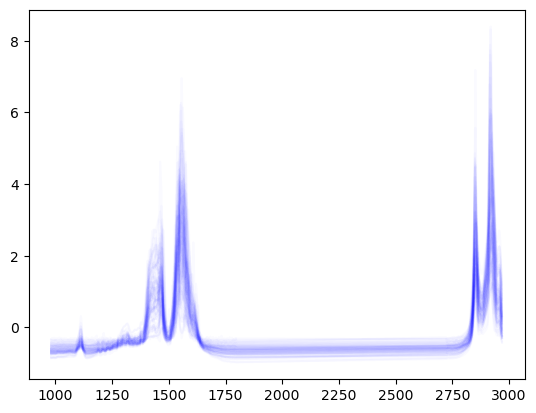

Magnesium Stearate v2


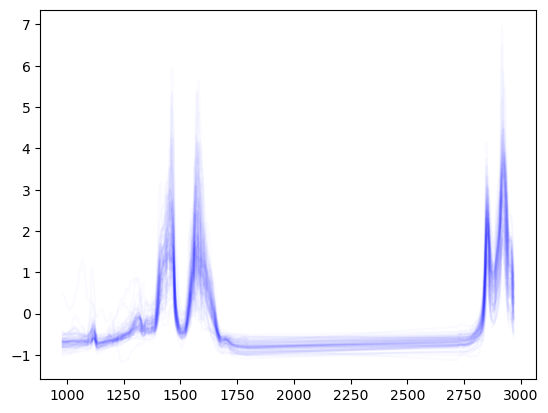

Sodium Stearate


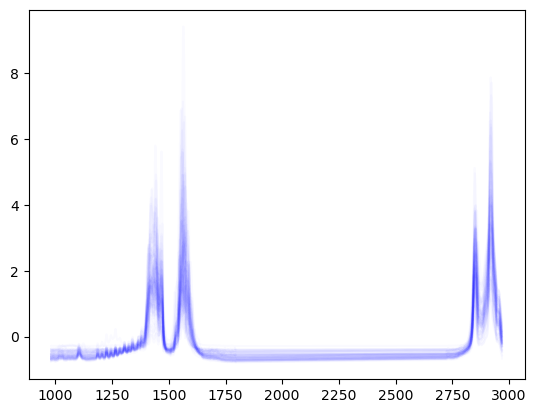

Zinc Stearate


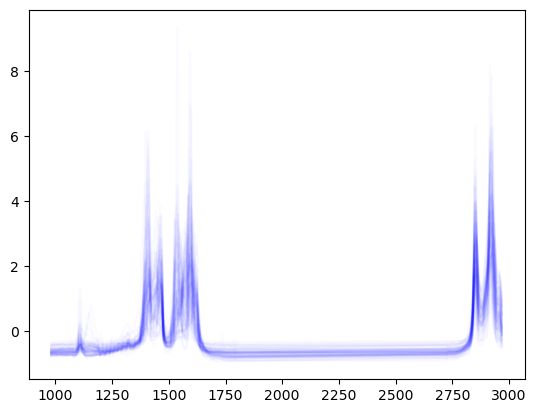

In [12]:
for label in np.unique(y_train_ir):
    print(label)
    _ = plt.plot(wn,
             X_ir[y_ir == label,:].T, c='b', alpha=.02)
    _ = plt.show()

Calcium Stearate
Magnesium Stearate v2
Sodium Stearate
Zinc Stearate


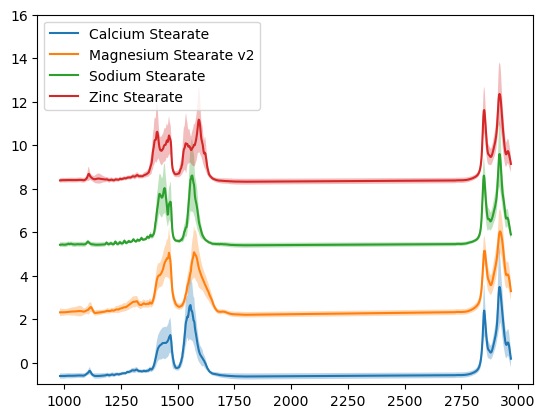

In [33]:
for i, label in enumerate(np.unique(y_train_ir)):
    print(label)
    y = i*3 + X_ir[y_ir == label,:].mean(0).T
    y_std = X_ir[y_ir == label,:].std(0).T
    _ = plt.plot(wn,
             y, label=label)
    
    _ = plt.fill_between(wn, y - y_std, y + y_std, alpha=.3)
    _ = plt.ylim(-1,16)
    _ = plt.legend()
    
    #_ = plt.show()

In [34]:
stearates_data_ir.to_csv('stearates_library_ir.csv')

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2960.856689453125,2962.785888671875,2964.71484375,2966.643798828125,2968.57275390625,map_x,map_y,id,material,in_library
0,-0.675534,-0.674187,-0.676164,-0.677512,-0.676342,-0.673528,-0.673201,-0.675380,-0.676044,-0.675955,...,0.642383,0.493054,0.340156,0.193000,0.063008,11231.849609,214.850006,Magnesium Stearate v2_1,Magnesium Stearate v2,1.0
1,-0.693635,-0.696416,-0.701324,-0.706167,-0.711282,-0.716251,-0.721704,-0.723549,-0.721428,-0.718515,...,1.007395,0.965420,0.888698,0.784624,0.684637,11279.049805,216.600006,Magnesium Stearate v2_2,Magnesium Stearate v2,1.0
2,-0.692647,-0.693295,-0.687913,-0.684325,-0.681512,-0.679313,-0.680552,-0.678067,-0.673682,-0.669751,...,0.301285,0.210615,0.113115,0.000349,-0.111578,11255.250000,216.600006,Magnesium Stearate v2_3,Magnesium Stearate v2,1.0
3,-0.940120,-0.942183,-0.938993,-0.929239,-0.914637,-0.900830,-0.893118,-0.891615,-0.896755,-0.906499,...,0.022649,-0.085364,-0.159528,-0.184049,-0.214074,11216.599609,218.699997,Magnesium Stearate v2_4,Magnesium Stearate v2,1.0
4,-0.632855,-0.637773,-0.641436,-0.643244,-0.635807,-0.625978,-0.617085,-0.608624,-0.596049,-0.578634,...,-0.287346,-0.372035,-0.446433,-0.514453,-0.582863,11348.250000,254.100006,Magnesium Stearate v2_5,Magnesium Stearate v2,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311,-0.598982,-0.601600,-0.608833,-0.607913,-0.598026,-0.597362,-0.591982,-0.588038,-0.591854,-0.598374,...,-0.327372,-0.350094,-0.408934,-0.451611,-0.461317,10437.250000,-1466.050049,Zinc Stearate_107,Zinc Stearate,1.0
312,-0.692782,-0.702264,-0.692153,-0.703968,-0.695667,-0.691210,-0.692771,-0.696071,-0.697907,-0.699064,...,-0.086340,-0.220806,-0.277223,-0.306242,-0.403612,10423.900391,-1464.800049,Zinc Stearate_108,Zinc Stearate,1.0
313,-0.658094,-0.668548,-0.670447,-0.664076,-0.651426,-0.648725,-0.645287,-0.638012,-0.635143,-0.633217,...,0.589333,0.453168,0.333181,0.190004,0.034273,10464.000000,-1458.449951,Zinc Stearate_109,Zinc Stearate,1.0
314,-0.746370,-0.746520,-0.747310,-0.748197,-0.749398,-0.750353,-0.751858,-0.753229,-0.753672,-0.753272,...,1.679791,1.547962,1.393496,1.223780,1.035223,10499.500000,-1452.949951,Zinc Stearate_110,Zinc Stearate,1.0
